# Тема 7. Анализ характеристик музыкальных треков для поиска паттернов популярности и жанровой принадлежности

**Студент:** Виноградова Валерия Михайловна, группа ИД24-3



## 2.1. Анализ целей проекта

**Бизнес-цели**

* Предсказать популярность трека, чтобы оценить релиз до вложений (для лейблов).
* Улучшить алгоритм рекомендаций: размечать жанры по аудио-признакам (для платформ).
* Дать маркетологам инструмент для анализа трендов: какие жанры и характеристики растут в популярности по годам и регионам.

**Критерии достижения целей**

* Прогноз популярности. Популярность в Spotify — число от 0 до 100. Качество модели оцениваем метрикой R² (какую долю разброса объясняет модель). Цель: R² ≥ 0,65.
* Жанровая классификация. Жанров 10–15. Качество оцениваем метрикой macro-F1 (средняя точность по всем жанрам, где каждый жанр весит одинаково). Обычная accuracy не подходит: если 80 % треков поп, модель может всегда отвечать «поп», получить 80 % и быть бесполезной. Цель: macro-F1 ≥ 0,70.
* Факторы популярности. Нужно минимум 3 признака, которые значимо влияют на популярность. Проверка через p-value: p < 0,05 означает, что связь значима.

**Объект и предмет исследования**

* Объект: музыкальные треки из открытых источников (Spotify, Discogs, Deezer, Pitchfork).
* Предмет: связь аудио-признаков (`tempo`, `energy`, `danceability`, `valence`, `loudness`) с популярностью и жанром трека.

**Границы исследования:** треки 2010–2024 годов.

**Гипотеза:** популярность трека зависит от сочетания `energy`, `danceability`, `valence`, `loudness` и `tempo`, причём эта зависимость различается по жанрам.

## 2.2. Подбор источников данных и выбор характеристик

По методичке нужен минимум один источник каждого типа. Выбраны четыре источника:

| № | Источник | Формат | Зачем |
|---|---|---|---|
| 1 | Spotify tracks (Kaggle) | CSV, реляционный | аудио-признаки и целевая `popularity` |
| 2 | Discogs masters | XML, иерархический | жанры и стили (целевая переменная классификации) |
| 3 | Deezer API | JSON, API | независимая популярность (`rank`), `bpm`, `gain` |
| 4 | Pitchfork Reviews (Kaggle) | SQLite + текст | жанры, оценки критиков, тексты рецензий |

В таблице Spotify нет жанра, поэтому жанры берём из Discogs (около 15 крупных жанров) и Pitchfork (9 жанров). Страны релиза в выбранных источниках нет, региональный срез делаем по языку трека (`language`, Spotify). Дамп Discogs большой, поэтому он читается потоком из интернета и на диск не сохраняется.

In [1]:
import time, os, re, gzip, sqlite3, datetime
import urllib.request, urllib.parse
import xml.etree.ElementTree as ET
from concurrent.futures import ThreadPoolExecutor

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

YEAR_MIN, YEAR_MAX = 2010, 2024
timings = {}   # сюда пишем время каждого этапа

# сайт Discogs может не пускать запросы без User-Agent
headers = {'User-Agent': 'Mozilla/5.0 (TOBD course project)'}

def open_dump(path_or_url):
    # открывает дамп: локальный файл, если он есть, иначе поток из интернета
    if os.path.exists(path_or_url):
        return open(path_or_url, 'rb')
    return urllib.request.urlopen(urllib.request.Request(path_or_url, headers=headers))

### 1. Spotify tracks: реляционный набор (CSV)

Одна строка — один трек. Есть метаданные, аудио-признаки Spotify, год и целевая переменная `popularity` (0–100).

In [2]:
spotify_df = pd.read_csv('spotify_tracks.csv')

print(spotify_df.shape)
display(spotify_df.head(3))
print(spotify_df.isnull().sum().sum())

(62317, 22)


,track_id,track_name,artist_name,year,popularity,artwork_url,album_name,acousticness,danceability,duration_ms,...,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,track_url,language
0,2r0ROhr7pRN4MXDMT1fEmd,"Leo Das Entry (From ""Leo"")",Anirudh Ravichander,2024,59,https://i.scdn.co/image/ab67616d0000b273ce9c65...,"Leo Das Entry (From ""Leo"")",0.0241,0.753,97297.0,...,8.0,0.1000,-5.994,0.0,0.1030,110.997,4.0,0.459,https://open.spotify.com/track/2r0ROhr7pRN4MXD...,Tamil
1,4I38e6Dg52a2o2a8i5Q5PW,AAO KILLELLE,"Anirudh Ravichander, Pravin Mani, Vaishali Sri...",2024,47,https://i.scdn.co/image/ab67616d0000b273be1b03...,AAO KILLELLE,0.0851,0.780,207369.0,...,10.0,0.0951,-5.674,0.0,0.0952,164.995,3.0,0.821,https://open.spotify.com/track/4I38e6Dg52a2o2a...,Tamil
2,59NoiRhnom3lTeRFaBzOev,Mayakiriye Sirikiriye - Orchestral EDM,"Anirudh Ravichander, Anivee, Alvin Bruno",2024,35,https://i.scdn.co/image/ab67616d0000b27334a1dd...,Mayakiriye Sirikiriye (Orchestral EDM),0.0311,0.457,82551.0,...,2.0,0.0831,-8.937,0.0,0.1530,169.996,4.0,0.598,https://open.spotify.com/track/59NoiRhnom3lTeR...,Tamil


0


| Колонка | Что означает |
|---|---|
| `track_id` | уникальный id трека (ключ) |
| `track_name`, `album_name` | название трека и альбома |
| `artist_name` | исполнитель (если несколько, через запятую) |
| `year` | год выхода |
| `language` | язык трека |
| `popularity` | популярность 0–100 (целевая переменная) |
| `acousticness` | насколько звук акустический, 0–1 |
| `danceability` | пригодность для танца, 0–1 |
| `energy` | интенсивность и «шумность», 0–1 |
| `instrumentalness` | вероятность отсутствия вокала, 0–1 |
| `liveness` | вероятность живой записи, 0–1 |
| `speechiness` | доля речи, 0–1 |
| `valence` | позитивность настроения, 0–1 |
| `loudness` | средняя громкость, дБ |
| `tempo` | темп, ударов в минуту |
| `duration_ms` | длительность, мс |
| `key`, `mode` | тональность (0–11) и лад (1 мажор, 0 минор) |
| `time_signature` | музыкальный размер (доли в такте) |
| `artwork_url`, `track_url` | ссылки на обложку и трек (служебные) |

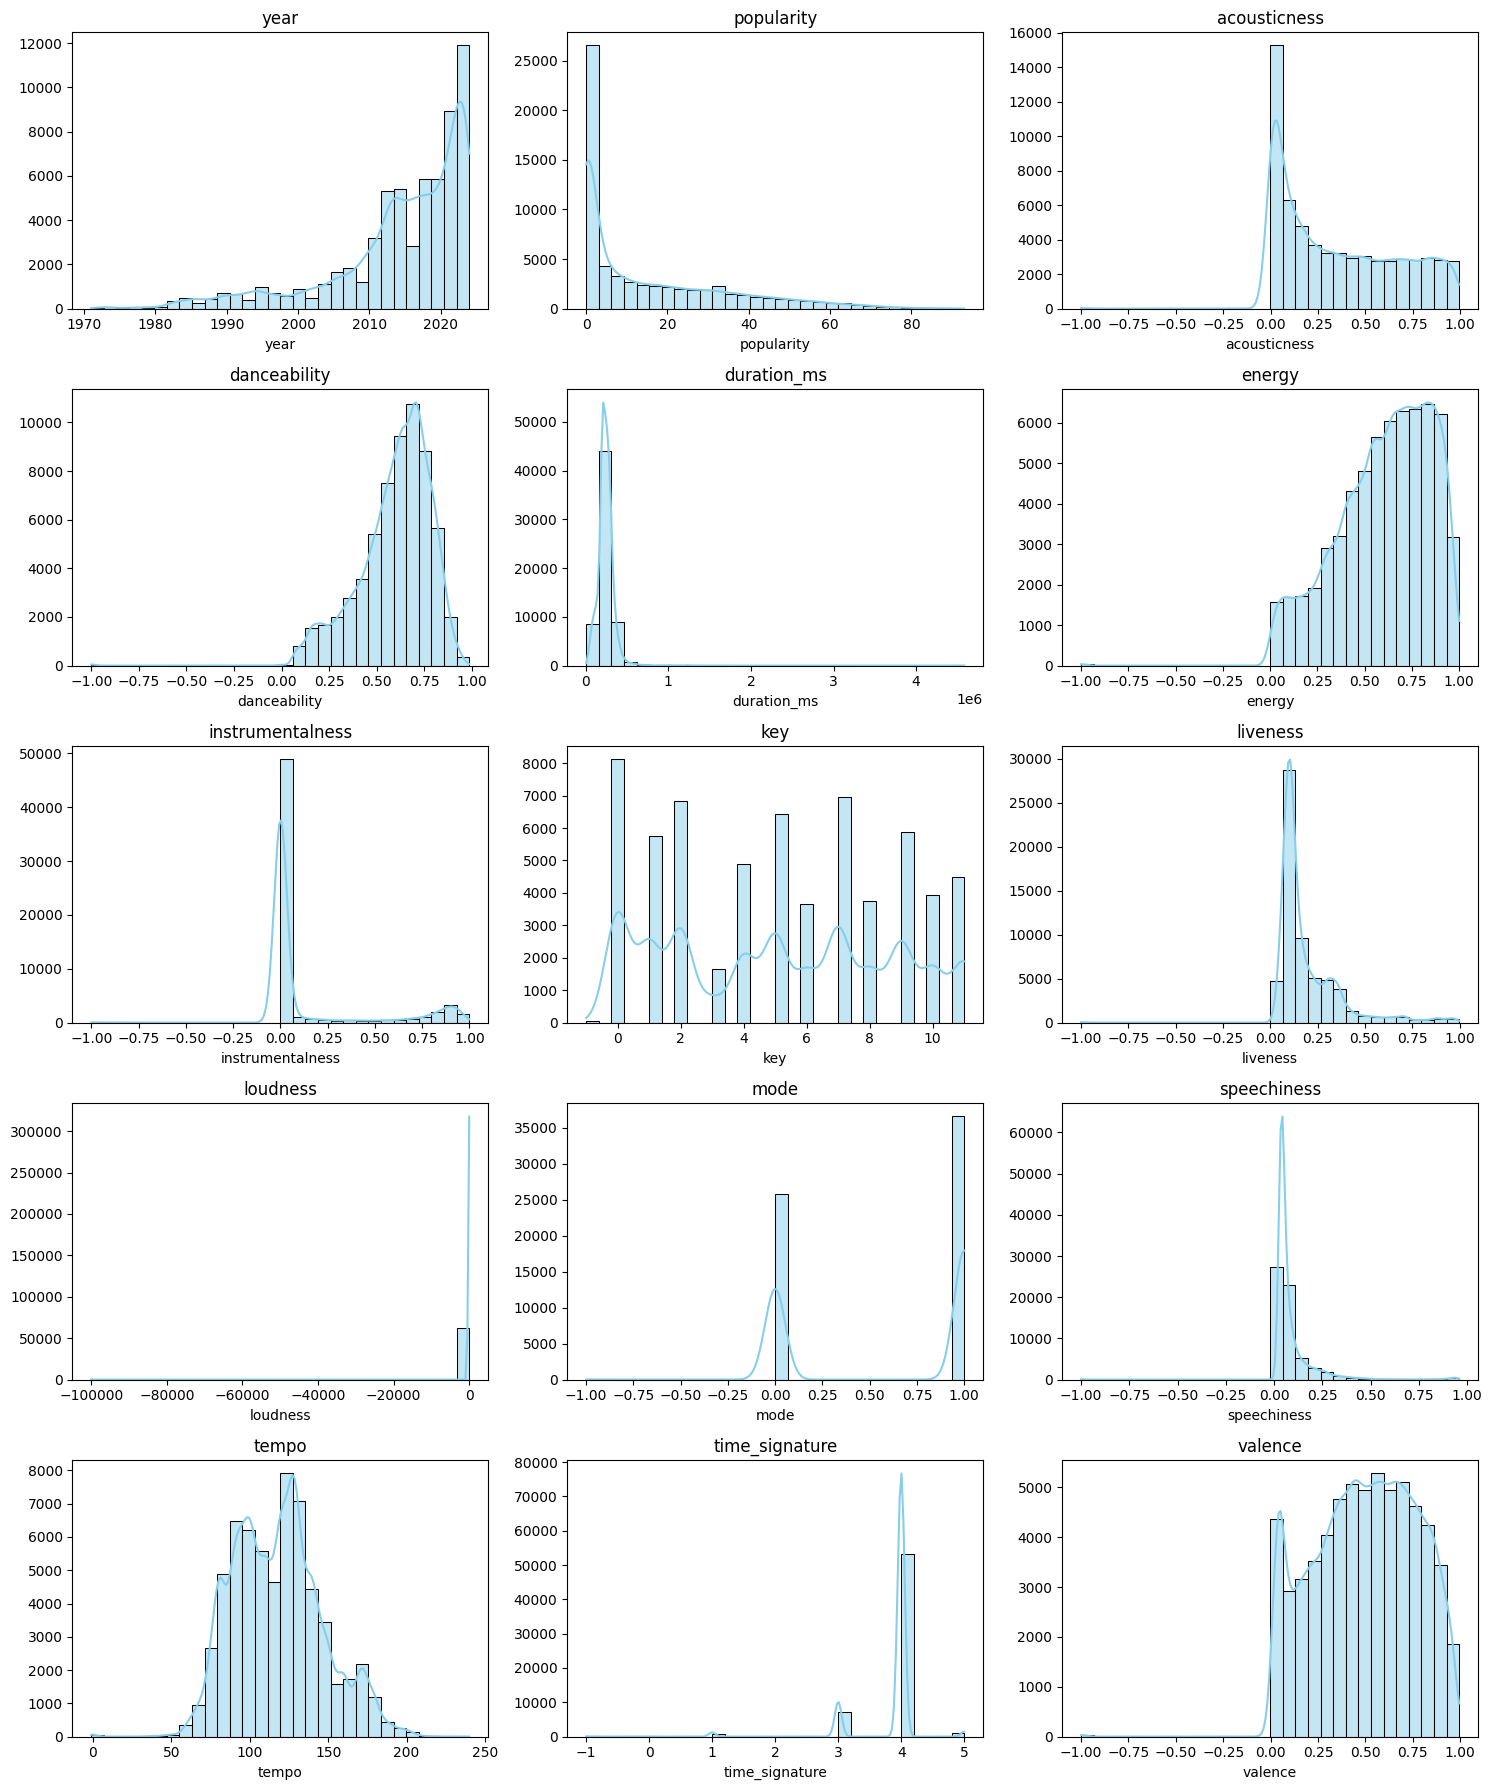

In [3]:
num_cols = [
    'year', 'popularity', 'acousticness', 'danceability', 'duration_ms',
    'energy', 'instrumentalness', 'key', 'liveness', 'loudness',
    'mode', 'speechiness', 'tempo', 'time_signature', 'valence'
]

fig, axes = plt.subplots(5, 3, figsize=(15, 18))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(spotify_df[col], bins=30, kde=True, ax=axes[i], color='skyblue')
    axes[i].set_title(col)
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

Ключевые признаки: `energy` — интенсивность (0–1), `danceability` — танцевальность (0–1), `valence` — позитивность (0–1), `loudness` — громкость в дБ, `tempo` — темп в ударах в минуту. Колонки с жанром в таблице нет.

### 2. Discogs masters: иерархический набор (XML)

Discogs каждый месяц выкладывает дампы в формате XML. Берём файл `masters`: один мастер-релиз — один альбом или сингл, независимо от переизданий. У каждого мастера есть жанры (`genres`) и стили (`styles`). Дампы лежат на `data.discogs.com`. Файл `masters` весит около 600 МБ в архиве; мы читаем его прямо из интернета через `gzip` и `iterparse`. 

In [5]:
discogs_url = 'https://data.discogs.com/?download=data%2F2026%2Fdiscogs_20261101_masters.xml.gz'
def print_tree(el, level=0):
    print('  ' * level + el.tag)
    seen = set()
    for child in el:
        if child.tag not in seen:
            seen.add(child.tag)
            print_tree(child, level + 1)

resp = open_dump(discogs_url)
gz = gzip.GzipFile(fileobj=resp)
for event, el in ET.iterparse(gz, events=('end',)):
    if el.tag == 'master':
        first_master = el
        break
resp.close()

print_tree(first_master)
print(first_master.get('id'), first_master.findtext('title'), first_master.findtext('year'),
      [g.text for g in first_master.findall('genres/genre')],
      [s.text for s in first_master.findall('styles/style')])

master
  main_release
  artists
    artist
      id
      name
      join
  genres
    genre
  styles
    style
  year
  title
  data_quality
  videos
    video
      title
      description
113 Moments In Time 2002 ['Electronic'] ['Techno', 'Tech House']


In [27]:

resp = open_dump(discogs_url)
gz = gzip.GzipFile(fileobj=resp)
print(gz.read(1500).decode('utf-8', errors='ignore'))
resp.close()

# 2. Первый мастер-релиз с отступами, чтобы вложенность читалась
ET.indent(first_master)
print(ET.tostring(first_master, encoding='unicode')[:1500])

<masters>
<master id="113"><main_release>116925</main_release><artists><artist><id>3225</id><name>Vince Watson</name><join>,</join></artist></artists><genres><genre>Electronic</genre></genres><styles><style>Techno</style><style>Tech House</style></styles><year>2002</year><title>Moments In Time</title><data_quality>Correct</data_quality><videos><video src="https://www.youtube.com/watch?v=dhbf58AU5ek" duration="321" embed="true"><title>Out of the Deep</title><description>Provided to YouTube by EPM Online

Out of the Deep · Vince Watson

Alola Vol 1

℗ Westbury Music Ltd / Spherecom Music

Released on: 1999-05-02

Auto-generated by YouTube.</description></video><video src="https://www.youtube.com/watch?v=xWY_I9QuWZM" duration="355" embed="true"><title>Mystical Rhythm</title><description>Provided to YouTube by EPM Online

Mystical Rhythm · Vince Watson

Alola Vol 1

℗ Westbury Music Ltd / Spherecom Music

Released on: 1999-05-02

Auto-generated by YouTube.</description></video><video src="

### 3. Deezer API: источник с API и выдачей в JSON

Открытый API Deezer работает без ключа. Для трека он отдаёт `rank` (независимая мера популярности), `bpm`, `gain` (громкость в дБ), длительность, дату выхода, `isrc` и флаг `explicit_lyrics`. Сначала ищем трек по исполнителю и названию, потом запрашиваем его карточку по `id`.

In [6]:
found = requests.get('https://api.deezer.com/search', params={'q': 'A.R. Rahman Dil Se Re', 'limit': 3}).json()
print(found['total'])
print(list(found['data'][0].keys()))

track = requests.get(f"https://api.deezer.com/track/{found['data'][0]['id']}").json()
print({k: track[k] for k in ['title', 'rank', 'bpm', 'gain', 'duration', 'release_date', 'isrc', 'explicit_lyrics']})

3
['id', 'readable', 'title', 'title_short', 'title_version', 'isrc', 'link', 'duration', 'rank', 'explicit_lyrics', 'explicit_content_lyrics', 'explicit_content_cover', 'preview', 'md5_image', 'artist', 'album', 'type']
{'title': 'Dil Se Re', 'rank': 196975, 'bpm': 0, 'gain': -17.4, 'duration': 405, 'release_date': '1998-07-08', 'isrc': 'INV119800031', 'explicit_lyrics': False}


In [26]:
import json

print(json.dumps(found['data'][0], indent=2, ensure_ascii=False))   # первый результат поиска
print(json.dumps(track, indent=2, ensure_ascii=False))              # полная карточка трека

{
  "id": 127772713,
  "readable": true,
  "title": "Dil Se Re",
  "title_short": "Dil Se Re",
  "title_version": "",
  "isrc": "INV119800031",
  "link": "https://www.deezer.com/track/127772713",
  "duration": 405,
  "rank": 196975,
  "explicit_lyrics": false,
  "explicit_content_lyrics": 0,
  "explicit_content_cover": 2,
  "preview": "https://cdnt-preview.dzcdn.net/api/1/1/e/6/0/0/e60e0bfc4ebc34df5216b40ecdb7f803.mp3?hdnea=exp=1793565236~acl=/api/1/1/e/6/0/0/e60e0bfc4ebc34df5216b40ecdb7f803.mp3*~data=user_id=0,application_id=42~hmac=a581d17ffc4f5198a0de69442b8765882174feb655405d6a8b5488ca336f4aa5",
  "md5_image": "352ed3819432c7442ebe203d74f08ac0",
  "artist": {
    "id": 491,
    "name": "A.R. Rahman",
    "link": "https://www.deezer.com/artist/491",
    "picture": "https://api.deezer.com/artist/491/image",
    "picture_small": "https://cdn-images.dzcdn.net/images/artist/bd34315ef977a62a9e28c1ab19bb8ac4/56x56-000000-80-0-0.jpg",
    "picture_medium": "https://cdn-images.dzcdn.net/ima

* `id` — номер трека
* `readable` — можно ли воспроизвести трек (да/нет)
* `title` — название
* `title_short` — короткое название
* `title_version` — версия (например, Live, Remastered)
* `isrc` — международный код записи
* `link` — ссылка на трек
* `duration` — длительность, секунды
* `rank` — рейтинг популярности: чем больше, тем популярнее
* `explicit_lyrics` — есть ли откровенный текст (да/нет)
* `explicit_content_lyrics` — то же, но числом-кодом
* `explicit_content_cover` — откровенная ли обложка (число-код)
* `preview` — ссылка на 30 секунд трека
* `md5_image` — код обложки
* `artist` — исполнитель (внутри: id, имя)
* `album` — альбом (внутри: id, название)
* `type` — тип объекта, здесь всегда `track` (трек)

### 4. Pitchfork Reviews: SQLite и неструктурированный текст

База рецензий на альбомы. Таблица `reviews` — оценка критика (`score`), год, автор; `genres` — жанры альбома; `content` — полный текст рецензии. Текст — неструктурированные данные, в 2.3 мы его векторизуем.

In [7]:
conn = sqlite3.connect('database.sqlite')
print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn))
display(pd.read_sql("SELECT reviewid, title, artist, score, best_new_music, pub_year FROM reviews LIMIT 3", conn))
text = pd.read_sql("SELECT content FROM content LIMIT 1", conn).iloc[0, 0]
print(text[:300])
conn.close()

      name
0  reviews
1  artists
2   genres
3   labels
4    years
5  content


,reviewid,title,artist,score,best_new_music,pub_year
0,22703,mezzanine,massive attack,9.3,0,2017
1,22721,prelapsarian,krallice,7.9,0,2017
2,22659,all of them naturals,uranium club,7.3,0,2017


“Trip-hop” eventually became a ’90s punchline, a music-press shorthand for “overhyped hotel lounge music.” But today, the much-maligned subgenre almost feels like a secret precedent. Listen to any of the canonical Bristol-scene albums of the mid-late ’90s, when the genre was starting to chafe agains


### 5. Итог: выбранные характеристики

**Итог 2.2.**

* Целевые переменные: `popularity` (Spotify, регрессия; проверка по `rank` Deezer) и жанр (Discogs и Pitchfork, классификация).
* Предикторы гипотезы: `energy`, `danceability`, `valence`, `loudness`, `tempo` (Spotify) и их аналоги `bpm`, `gain` (Deezer).
* Факторы влияния: год, язык трека, стили Discogs, оценка критика и текст рецензии (Pitchfork), `explicit` (Deezer).
* Требования методички выполнены: реляционный набор (Spotify, Pitchfork), иерархический XML (Discogs), API с JSON (Deezer), неструктурированные данные (тексты рецензий). В каждом источнике не меньше 3 числовых и 3 категориальных характеристик, везде есть время.

## 2.3. Подготовка данных 

### 1. Spotify (CSV): загрузка, пропуски, очистка

In [8]:
t0 = time.time()
spotify_df = pd.read_csv('spotify_tracks.csv')
timings['1.1 Spotify: загрузка'] = round(time.time() - t0, 2)

audio_cols = ['acousticness', 'danceability', 'energy', 'instrumentalness', 'liveness',
              'speechiness', 'valence', 'loudness', 'tempo', 'duration_ms', 'popularity']
display(spotify_df[audio_cols].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
acousticness,62317.0,0.362,0.315,-1.0,0.067,0.286,0.632,0.996
danceability,62317.0,0.597,0.186,-1.0,0.497,0.631,0.730,0.986
energy,62317.0,0.602,0.246,-1.0,0.440,0.639,0.803,1.000
instrumentalness,62317.0,0.146,0.308,-1.0,0.000,0.000,0.015,0.999
liveness,62317.0,0.194,0.172,-1.0,0.093,0.125,0.243,0.998
speechiness,62317.0,0.088,0.115,-1.0,0.037,0.049,0.089,0.959
valence,62317.0,0.495,0.265,-1.0,0.292,0.507,0.710,0.995
loudness,62317.0,-65.103,2369.051,-100000.0,-10.727,-7.506,-5.456,1.233
tempo,62317.0,117.931,28.509,-1.0,95.942,117.991,135.081,239.970
duration_ms,62317.0,242527.040,112999.933,5000.0,192160.000,236267.000,286240.000,4581483.000


In [9]:
t0 = time.time()
sp = spotify_df.drop_duplicates('track_id')
sp = sp[sp['year'].between(YEAR_MIN, YEAR_MAX)]

# isnull() показал 0 пропусков, но в describe() видны заглушки -1 и -100000: так закодированы пропуски
share_cols = ['acousticness', 'danceability', 'energy', 'instrumentalness', 'liveness', 'speechiness', 'valence']
sp = sp[(sp[share_cols] >= 0).all(axis=1) & (sp['loudness'] > -60) & (sp['tempo'] > 0) & (sp['duration_ms'] > 0)].copy()
timings['1.2 Spotify: очистка'] = round(time.time() - t0, 2)

print(len(spotify_df), '->', len(sp), '| доля popularity = 0:', round((sp['popularity'] == 0).mean(), 3))

62317 -> 49212 | доля popularity = 0: 0.282


Для слияния нужны ключи. Названия приводим к нижнему регистру, убираем скобки вроде (feat. X) и [Remastered], суффиксы  - Live и знаки препинания; у списка исполнителей берём первого.

In [10]:
def norm(s):
    s = str(s).casefold() if pd.notna(s) else ''
    s = re.sub(r'\(.*?\)|\[.*?\]', ' ', s)    # (feat. X), [Remastered], (2) у Discogs
    s = re.sub(r'\s+-\s+.*$', '', s)          # " - Live"
    s = re.sub(r'[^\w\s]', ' ', s)
    return re.sub(r'\s+', ' ', s).strip()

def main_artist(s):
    s = str(s) if pd.notna(s) else ''
    return re.split(r',|;|\sfeat\.?\s|\sft\.?\s|\s&\s|\sx\s', s)[0]

def make_key(artist, name):
    a = artist.map(main_artist).map(norm)
    n = name.map(norm)
    return (a + '|' + n).where((a != '') & (n != ''))   # пустой ключ -> NaN

sp['key_aa'] = make_key(sp['artist_name'], sp['album_name'])

### 2. Discogs masters (XML): чтение дампа из интернета

Читаем файл потоком: скачивается кусок, разбирается, память очищается. Оставляем только мастера 2010–2024. 

In [12]:
def read_discogs(url):
    rows = []
    events = ET.iterparse(gzip.GzipFile(fileobj=open_dump(url)), events=('start', 'end'))
    root = next(events)[1]      # корневой элемент: чистим его, чтобы память не росла
    for event, el in events:
        if event == 'end' and el.tag == 'master':
            year = int(el.findtext('year') or 0)
            if YEAR_MIN <= year <= YEAR_MAX:
                rows.append({
                    'master_id': el.get('id'), 'title': el.findtext('title'), 'year': year,
                    'artist': el.findtext('artists/artist/name'),
                    'genre': el.findtext('genres/genre'), 'style': el.findtext('styles/style'),
                    'n_genres': len(el.findall('genres/genre')), 'n_styles': len(el.findall('styles/style')),
                    'n_artists': len(el.findall('artists/artist')), 'n_videos': len(el.findall('videos/video')),
                    'data_quality': el.findtext('data_quality')})
            el.clear()
            root.clear()
    return pd.DataFrame(rows)

t0 = time.time()
dc_raw = read_discogs(discogs_url)
timings['2.1 Discogs: чтение XML'] = round(time.time() - t0, 2)

print(len(dc_raw), 'мастеров за', YEAR_MIN, '-', YEAR_MAX)
print(dc_raw['genre'].value_counts())

695444 мастеров за 2010 - 2024
genre
Electronic                301812
Rock                      249480
Hip Hop                    36531
Pop                        32272
Jazz                       23731
Folk, World, & Country     15723
Classical                   8798
Funk / Soul                 8704
Reggae                      4756
Latin                       4175
Stage & Screen              3463
Blues                       2805
Non-Music                   2557
Children's                   551
Brass & Military              86
Name: count, dtype: int64


In [13]:
dc = dc_raw.drop_duplicates('master_id').dropna(subset=['title', 'artist']).copy()
dc = dc[~dc['artist'].str.lower().isin(['various', 'unknown artist'])]   # сборники
dc['key_aa'] = make_key(dc['artist'], dc['title'])
print(len(dc), 'мастеров;', dc['genre'].nunique(), 'жанров;', dc['style'].nunique(), 'стилей')

667724 мастеров; 15 жанров; 659 стилей


### 3. Deezer API (JSON): независимая популярность, bpm, gain

Берём случайную выборку из N_DEEZER треков Spotify. Для каждого: поиск → проверка, что исполнитель и название совпали → запрос карточки. Запросы идут в 5 потоков с паузой, чтобы не превысить лимит Deezer (около 10 запросов в секунду). Результат сохраняем в `deezer_raw.csv`, чтобы не ждать повторно.

In [15]:
N_DEEZER = 1000

def deezer_info(row):
    time.sleep(0.5)     # пауза, чтобы не превысить лимит Deezer
    a, t = main_artist(row['artist_name']), norm(row['track_name'])
    try:
        for c in requests.get('https://api.deezer.com/search', params={'q': f'{a} {t}', 'limit': 5}).json()['data']:
            if norm(c['title']) == t and norm(c['artist']['name']) == norm(a):    # совпали название и исполнитель
                d = requests.get(f"https://api.deezer.com/track/{c['id']}").json()
                return {'track_id': row['track_id'], 'matched': True, 'dz_rank': d['rank'], 'dz_duration': d['duration'],
                        'dz_bpm': d['bpm'] or None, 'dz_gain': d['gain'], 'dz_explicit': d['explicit_lyrics'],
                        'dz_release_date': d['release_date'], 'dz_n_contributors': len(d['contributors']),
                        'dz_artist': c['artist']['name'], 'dz_album': c['album']['title']}
    except Exception:
        pass            # запрос не удался: считаем трек ненайденным
    return {'track_id': row['track_id'], 'matched': False}

t0 = time.time()
with ThreadPoolExecutor(max_workers=5) as ex:
    dz_raw = pd.DataFrame(list(ex.map(deezer_info, sp.sample(N_DEEZER, random_state=42).to_dict('records'))))
dz_raw.to_csv('deezer_raw.csv', index=False)
timings['3.1 Deezer: запросы к API'] = round(time.time() - t0, 2)

print('найдено на Deezer:', round(dz_raw['matched'].mean(), 3), 'из', len(dz_raw))

найдено на Deezer: 0.772 из 1000


In [17]:
dz = dz_raw[dz_raw['matched']].drop(columns='matched').copy()
print(len(dz), 'треков, из них с rank = 0:', (dz['dz_rank'] == 0).sum())
dz['dz_rank'] = dz['dz_rank'].replace(0, np.nan)    # rank = 0: данных о рейтинге нет, считаем пропуском
dz['dz_log_rank'] = np.log10(dz['dz_rank'])         # rank сильно скошен, берём логарифм
dz['dz_release_date'] = pd.to_datetime(dz['dz_release_date'], errors='coerce')

772 треков, из них с rank = 0: 3


### 4. Pitchfork (SQLite + текст): жанры, оценки, векторизация рецензий

In [18]:
conn = sqlite3.connect('database.sqlite')
pf_rev = pd.read_sql("SELECT reviewid, title, artist, score, best_new_music, author, pub_year FROM reviews", conn)
pf_gen = pd.read_sql("SELECT reviewid, genre FROM genres", conn)
pf_txt = pd.read_sql("SELECT reviewid, content FROM content", conn)
conn.close()

# у альбома может быть несколько жанров: главный = первый
gen = pf_gen.dropna().groupby('reviewid')['genre'].agg(pf_genre='first', pf_n_genres='nunique').reset_index()
pf = pf_rev.merge(gen, on='reviewid', how='left').merge(pf_txt, on='reviewid', how='left').drop_duplicates('reviewid')
pf['pf_word_count'] = pf['content'].fillna('').str.split().str.len()
pf['key_aa'] = make_key(pf['artist'], pf['title'])
print(pf.shape)
print(pf['pf_genre'].value_counts(dropna=False))

(18389, 12)
pf_genre
rock            9435
NaN             2365
electronic      1994
rap             1488
pop/r&b         1087
folk/country     574
experimental     565
metal            357
jazz             341
global           183
Name: count, dtype: int64


**Векторизация текста.** TF-IDF превращает каждую рецензию в вектор слов, а LSA (усечённое SVD) сжимает его до 50 чисел, которые можно подавать в модели. Для аннотирования смотрим характерные слова каждого жанра.

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

t0 = time.time()
tfidf = TfidfVectorizer(max_features=20000, stop_words='english', min_df=5, max_df=0.5, sublinear_tf=True)
X = tfidf.fit_transform(pf['content'].fillna(''))
svd = TruncatedSVD(n_components=50, random_state=42)
Z = svd.fit_transform(X)
timings['4.2 Pitchfork: TF-IDF + LSA'] = round(time.time() - t0, 2)

pf_vec = pd.DataFrame(Z, columns=[f'txt_lsa_{i:02d}' for i in range(50)])
pf_vec.insert(0, 'reviewid', pf['reviewid'].values)
print(X.shape, '| объяснено дисперсии:', round(svd.explained_variance_ratio_.sum(), 3))

words = np.array(tfidf.get_feature_names_out())
for g in pf['pf_genre'].dropna().unique():
    idx = np.where(pf['pf_genre'].values == g)[0]
    top = np.asarray(X[idx].mean(axis=0)).ravel().argsort()[::-1][:8]
    print(g, ':', ', '.join(words[top]))

(18389, 20000) | объяснено дисперсии: 0.037
electronic : tracks, techno, electronic, dance, house, bass, work, beats
metal : metal, black, death, hardcore, doom, riffs, minutes, bands
rock : rock, pop, ve, love, best, little, don, make
rap : rap, rapper, hop, hip, beats, rappers, mixtape, rapping
experimental : work, piece, noise, pieces, composer, electronic, tracks, long
folk/country : folk, country, voice, acoustic, sings, love, old, work
jazz : jazz, playing, work, bass, free, tracks, piano, piece
pop/r&b : pop, love, voice, best, tracks, debut, little, good
global : reggae, fela, african, africa, world, mali, dancehall, afrobeat


### 5. Типы шкал, аналитические роли и общие атрибуты

| Атрибут | Источник | Тип шкалы | Аналитическая роль |
|---|---|---|---|
| `popularity` | Spotify | отношений | **целевая** (регрессия) |
| `dz_rank` (и его log10) | Deezer | отношений | целевая-2 (независимая проверка популярности) |
| `energy`, `danceability`, `valence`, `acousticness`, `speechiness`, `instrumentalness`, `liveness` | Spotify | интервальная | признак |
| `loudness` | Spotify | интервальная | признак |
| `tempo`, `duration_ms` | Spotify | отношений | признак |
| `key`, `mode`, `time_signature` | Spotify | номинальная | признак |
| `language` | Spotify | номинальная | срез (регион) |
| `dz_bpm`, `dz_gain`, `dz_explicit` | Deezer | отношений / номинальная | признак, сверка со Spotify |
| `genre`, `style` | Discogs | номинальная | **целевая** (классификация жанров) |
| `pf_genre` | Pitchfork | номинальная | целевая-2 (жанры) |
| `score` | Pitchfork | порядковая | признак (оценка критика) |
| `txt_lsa_00…49` | Pitchfork (текст) | интервальная | признак (текст рецензии) |
| `year` | все источники | интервальная (время) | общий атрибут, агрегаты по годам |
| `track_id` | Spotify, Deezer | номинальная | ключ слияния (точный) |
| исполнитель + альбом | Spotify, Discogs, Pitchfork | номинальная | ключ слияния (по нормализованным названиям) |

**Общие атрибуты для слияния:** `track_id` (Spotify и Deezer), исполнитель + альбом (Spotify, Discogs, Pitchfork), год (все источники).

### 6. Слияние разнородных данных

Три уровня: трек (точно по `track_id`: Spotify и Deezer), альбом (по ключу «исполнитель + альбом»: Spotify, Discogs, Pitchfork) и год (общая таблица по годам). Базой служит Spotify (`left join`), поэтому число строк не должно измениться.

In [20]:
t0 = time.time()
dc_agg = (dc.drop_duplicates('key_aa').dropna(subset=['key_aa'])
            [['key_aa', 'master_id', 'genre', 'style', 'n_styles', 'n_genres']]
            .add_prefix('dc_').rename(columns={'dc_key_aa': 'key_aa'}))

pf_agg = (pf.drop(columns='content').merge(pf_vec, on='reviewid')
            .dropna(subset=['key_aa']).drop_duplicates('key_aa').drop(columns=['title', 'artist'])
            .rename(columns={'score': 'pf_score', 'best_new_music': 'pf_bnm', 'author': 'pf_author', 'pub_year': 'pf_year'}))

merged = (sp.merge(dz.drop(columns=['dz_artist', 'dz_album']), on='track_id', how='left')
            .merge(dc_agg, on='key_aa', how='left')
            .merge(pf_agg, on='key_aa', how='left'))

# у Pitchfork другие названия жанров (rap, pop/r&b ...), приводим их к названиям Discogs
pf_to_discogs = {'electronic': 'Electronic', 'rock': 'Rock', 'metal': 'Rock', 'rap': 'Hip Hop', 'pop/r&b': 'Pop',
                 'folk/country': 'Folk, World, & Country', 'global': 'Folk, World, & Country',
                 'jazz': 'Jazz', 'experimental': 'Experimental'}
# единая колонка жанра: сначала Discogs, если нет - Pitchfork
merged['genre_unified'] = merged['dc_genre'].fillna(merged['pf_genre'].map(pf_to_discogs))
timings['6.1 Слияние'] = round(time.time() - t0, 2)

print(merged.shape)
for col in ['dz_rank', 'dc_genre', 'pf_score', 'genre_unified']:
    print(col, ': данные есть у', round(merged[col].notna().mean() * 100, 1), '% треков Spotify')
print(merged['genre_unified'].value_counts())

(49212, 95)
dz_rank : данные есть у 1.6 % треков Spotify
dc_genre : данные есть у 17.6 % треков Spotify
pf_score : данные есть у 1.5 % треков Spotify
genre_unified : данные есть у 17.6 % треков Spotify
genre_unified
Electronic                3150
Pop                       2296
Stage & Screen            1134
Rock                       896
Hip Hop                    713
Folk, World, & Country     156
Classical                  102
Funk / Soul                 82
Latin                       79
Jazz                        43
Reggae                      11
Name: count, dtype: int64


In [30]:
print('Итоговая таблица:', merged.shape[0], 'треков,', merged.shape[1], 'колонок')

# в скольких источниках нашёлся трек (Spotify есть у всех)
n_src = 1 + merged['dz_rank'].notna() + merged['dc_genre'].notna() + merged['pf_score'].notna()
print(n_src.value_counts().sort_index().rename_axis('источников').rename('треков'))

Итоговая таблица: 49212 треков, 95 колонок
источников
1    39956
2     8339
3      900
4       17
Name: треков, dtype: int64


In [33]:
# все 95 колонок, сгруппированные по источникам
groups = {
    'Spotify (+ ключ key_aa)': list(sp.columns),
    'Deezer (dz_)': [c for c in merged.columns if c.startswith('dz_')],
    'Discogs (dc_)': [c for c in merged.columns if c.startswith('dc_')],
    'Pitchfork (pf_ и reviewid)': [c for c in merged.columns if c.startswith('pf_') or c == 'reviewid'],
    'Текст рецензии (txt_lsa_)': [c for c in merged.columns if c.startswith('txt_lsa_')],
    'Единый жанр': ['genre_unified']}

for name, cols_ in groups.items():
    print(name, '-', len(cols_), 'колонок:', cols_ if len(cols_) < 30 else cols_[:2] + ['...'] + cols_[-1:])
print('Всего:', sum(len(c) for c in groups.values()))

# все значения одного трека, у которого есть оценка и текст Pitchfork
pd.set_option('display.max_rows', 100)
display(merged[merged['pf_score'].notna()].iloc[0].to_frame('значение'))

Spotify (+ ключ key_aa) - 23 колонок: ['track_id', 'track_name', 'artist_name', 'year', 'popularity', 'artwork_url', 'album_name', 'acousticness', 'danceability', 'duration_ms', 'energy', 'instrumentalness', 'key', 'liveness', 'loudness', 'mode', 'speechiness', 'tempo', 'time_signature', 'valence', 'track_url', 'language', 'key_aa']
Deezer (dz_) - 8 колонок: ['dz_rank', 'dz_duration', 'dz_bpm', 'dz_gain', 'dz_explicit', 'dz_release_date', 'dz_n_contributors', 'dz_log_rank']
Discogs (dc_) - 5 колонок: ['dc_master_id', 'dc_genre', 'dc_style', 'dc_n_styles', 'dc_n_genres']
Pitchfork (pf_ и reviewid) - 8 колонок: ['reviewid', 'pf_score', 'pf_bnm', 'pf_author', 'pf_year', 'pf_genre', 'pf_n_genres', 'pf_word_count']
Текст рецензии (txt_lsa_) - 50 колонок: ['txt_lsa_00', 'txt_lsa_01', '...', 'txt_lsa_49']
Единый жанр - 1 колонок: ['genre_unified']
Всего: 95


,значение
track_id,15JINEqzVMv3SvJTAXAKED
track_name,Love The Way You Lie
artist_name,"Eminem, Rihanna"
year,2010
popularity,86
artwork_url,https://i.scdn.co/image/ab67616d0000b273c08d5f...
album_name,Recovery
acousticness,0.241
danceability,0.749
duration_ms,263373.0
